**Intro to Python: Working with Data**

# Visualization with matplotlib and pandas

This notebook is the hands-on companion to the Visualization section of the
"Fundamentals of Pandas" slides. You will first draw line, bar and pie charts
with matplotlib, the plotting library underneath pandas, and then plot the
Sherlock app data you met in Session 1 (`BigData-session-1.ipynb`).

<a id="TOC"></a>
**Quick Links** (sections of this notebook):

1. [Setup](#sec-Setup)
2. [Line Graphs](#sec-Line)
3. [Bar Charts](#sec-Bar)
4. [Pie Charts](#sec-Pie)
5. [Plotting pandas Data](#sec-Pandas)
6. [Summary & Further Resources](#sec-Summary)

### Reminder

* Throughout this notebook, `#TODO` is used as a placeholder where you need to fill in with something appropriate.
* To run a code in a cell, press `Shift+Enter`.
* **One plot per cell.** If a cell draws two charts, they are drawn on top of each other.

<a id="sec-Setup"></a>
## 1. Setup

matplotlib and seaborn are not part of the standard Python library.
If an import below fails with `ModuleNotFoundError`, run the install cell, restart the kernel, and run the import cell again.

In [ ]:
"""Run only if matplotlib or seaborn is missing""";
# !pip install matplotlib seaborn

In [1]:
"""Run this cell to import the libraries""";
import pandas
import matplotlib.pyplot as plt
import seaborn
%matplotlib inline

`matplotlib.pyplot` is almost always imported under the short name `plt`.
The last line is an IPython magic command that makes plots appear right below the cell
(outside Jupyter you would call `plt.show()` to display a plot).

<a id="sec-Line"></a>[(back to top)](#TOC)
## 2. Line Graphs

A line graph connects a series of points with straight lines.
`plt.plot(x, y)` takes two lists of the same length: the x coordinates and the y coordinates.
Each pair `(x[i], y[i])` becomes one point.

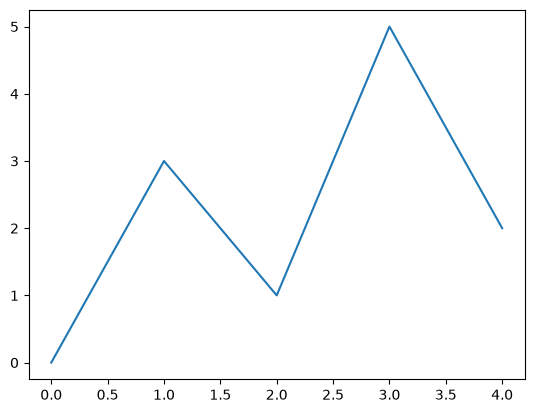

In [2]:
"""Run to draw a simple line graph""";
x_coords = [0, 1, 2, 3, 4]
y_coords = [0, 3, 1, 5, 2]

plt.plot(x_coords, y_coords)

**QUESTION**: The first point is `(0, 0)`. What are the second and third points? Find them on the graph.

**EXERCISE 1**: Predict what happens if you swap the two lists, `plt.plot(y_coords, x_coords)`. Then try it.
Also add the argument `marker='o'` to draw a dot at every point.

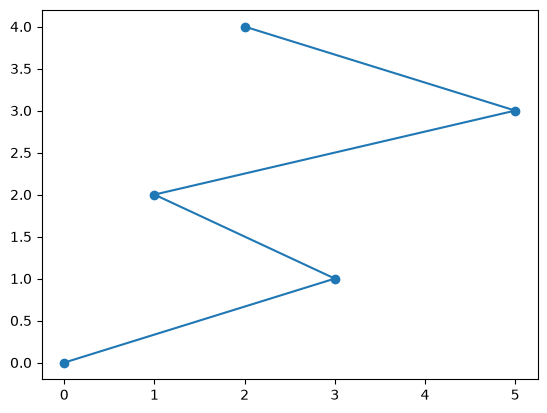

In [3]:
"""Swap the lists and add markers""";
#plt.plot(#TODO, #TODO, marker=#TODO)

plt.plot(y_coords, x_coords, marker="o")

### 2.1 Titles, Labels and Tick Marks

A chart without labels makes the reader guess. Each of these functions adds one piece;
call them after `plt.plot` in the same cell:

| Function | What it adds |
|:---|:---|
| `plt.title('...')` | a title above the chart |
| `plt.xlabel('...')`, `plt.ylabel('...')` | names for the x and y axes |
| `plt.xticks(positions, labels)` | your own text at chosen positions on the x axis |
| `plt.yticks(positions, labels)` | the same for the y axis |
| `plt.grid(True)` | a background grid |
| `plt.xlim(low, high)`, `plt.ylim(low, high)` | the range shown on each axis |

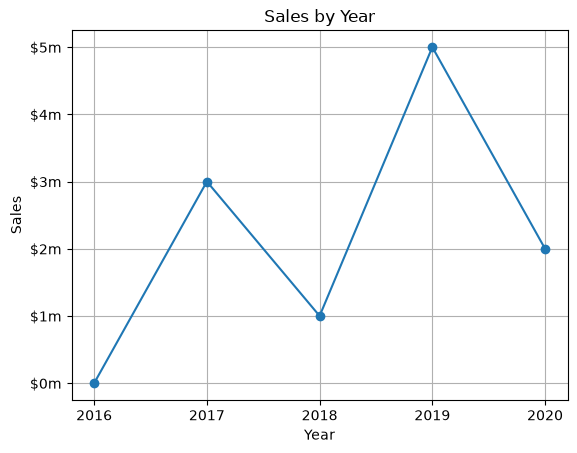

In [4]:
"""Run to draw a fully labeled line graph""";
plt.plot(x_coords, y_coords, marker='o')

plt.title('Sales by Year')
plt.xlabel('Year')
plt.ylabel('Sales')

plt.xticks([0, 1, 2, 3, 4],
           ['2016', '2017', '2018', '2019', '2020'])
plt.yticks([0, 1, 2, 3, 4, 5],
           ['$0m', '$1m', '$2m', '$3m', '$4m', '$5m'])
plt.grid(True)

**EXERCISE 2**: Copy the cell above into the cell below, then change it so that

* the y axis runs from 0 to 6 (use `plt.ylim`), and
* the title reads `Sales by Year (in millions)`.

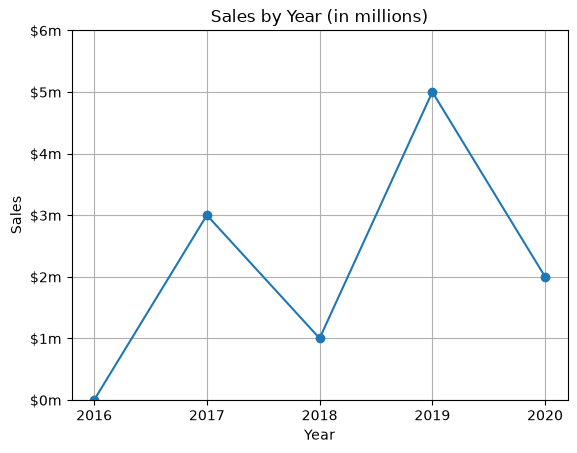

In [8]:
"""Use this cell for Exercise 2""";
#TODO

plt.plot(x_coords, y_coords, marker="o")

plt.title("Sales by Year (in millions)")
plt.xlabel("Year")
plt.ylabel("Sales")

plt.xticks([0, 1, 2, 3, 4], ["2016", "2017", "2018", "2019", "2020"])
plt.yticks([0, 1, 2, 3, 4, 5, 6], ["$0m", "$1m", "$2m", "$3m", "$4m", "$5m", "$6m"])
plt.ylim(0, 6)
plt.grid(True)

<a id="sec-Bar"></a>[(back to top)](#TOC)
## 3. Bar Charts

A bar chart compares amounts. `plt.bar(x, heights)` takes the position of each bar on the x axis
and the height of each bar.

* An optional third argument sets the bar **width** (default `0.8`).
* By default each bar is **centered** on its x value. Pass `align='edge'` to make each bar *start* at its x value instead.

<BarContainer object of 5 artists>

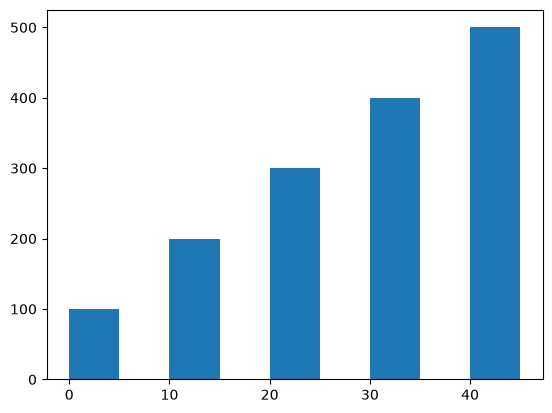

In [9]:
"""Run to draw a bar chart""";
left_edges = [0, 10, 20, 30, 40]
heights = [100, 200, 300, 400, 500]

plt.bar(left_edges, heights, 5, align='edge')

**QUESTION**: Remove the `5` from the call above and run it again. Why are the bars so thin now?

With 5 removed fromt the cell above and the result after runtime, it results in thin bars because matplotlib uses the default width of bars on a chart to be 0.8.


The `color` parameter takes one color code per bar:

| Code | Color | Code | Color |
|:---:|:---|:---:|:---|
| `'b'` | blue | `'m'` | magenta |
| `'g'` | green | `'y'` | yellow |
| `'r'` | red | `'k'` | black |
| `'c'` | cyan | `'w'` | white |

**EXERCISE 3**: Redraw the bar chart with red, green, blue, cyan and magenta bars, in that order,
and label the axes `Category` and `Amount`.

Text(0, 0.5, 'Amount')

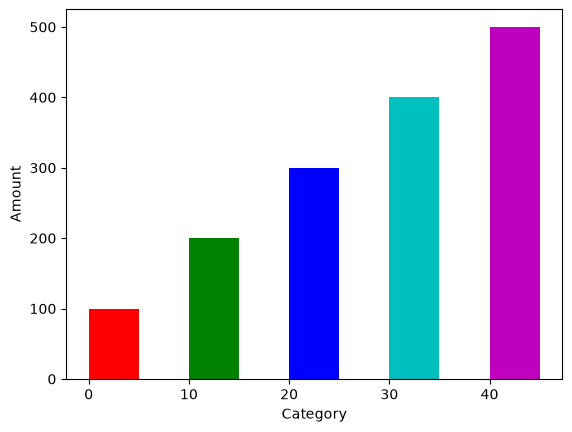

In [10]:
"""Use this cell for Exercise 3""";
#plt.bar(left_edges, heights, 5, align='edge', color=(#TODO))
#plt.xlabel(#TODO)
#plt.ylabel(#TODO)

plt.bar(left_edges, heights, 5, align="edge",
        color=["r", "g", "b", "c", "m"])
plt.xlabel("Category")
plt.ylabel("Amount")

<a id="sec-Pie"></a>[(back to top)](#TOC)
## 4. Pie Charts

A pie chart shows parts of a whole. `plt.pie(values)` adds up the values and gives each one a slice
sized by its share of the total. The `labels` parameter takes a list of names in the same order as the values.

Text(0.5, 1.0, 'Sales by Quarter')

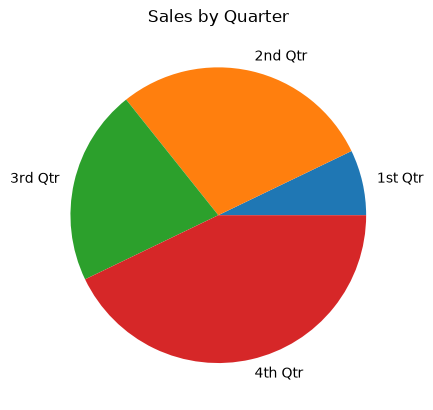

In [11]:
"""Run to draw a labeled pie chart""";
sales = [100, 400, 300, 600]
slice_labels = ['1st Qtr', '2nd Qtr', '3rd Qtr', '4th Qtr']

plt.pie(sales, labels=slice_labels)
plt.title('Sales by Quarter')

**QUESTION**: The total of `sales` is 1,400. What percentage of the pie should the 4th quarter fill? Does the chart agree?

Since 4th quarter is 600, that should cover 42.9% of the pie

**EXERCISE 4**: Redraw the pie chart

* with the slice colors red, green, blue and cyan, using the `colors` parameter (it works like `color` for bars), and
* with each slice's percentage printed on it, by adding the argument `autopct='%1.0f%%'`.

Text(0.5, 1.0, 'Sales by Quarter')

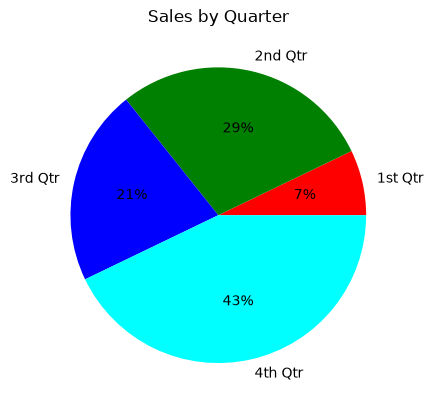

In [12]:
"""Use this cell for Exercise 4""";
#plt.pie(sales, labels=slice_labels, colors=(#TODO), autopct=#TODO)
#plt.title('Sales by Quarter')

plt.pie(
    sales,
    labels=slice_labels,
    colors=["red", "green", "blue", "cyan"],
    autopct="%1.0f%%"
)
plt.title("Sales by Quarter")

> **Pie or bar?** Pie charts work best with a few categories whose shares differ clearly.
> With many categories, or values that are close, a bar chart is easier to read.

<a id="sec-Pandas"></a>[(back to top)](#TOC)
## 5. Plotting pandas Data

Every pandas plot is drawn by matplotlib. A `Series` or `DataFrame` has a `.plot()` method, and its
`kind=` argument picks the chart: `'line'`, `'bar'`, `'pie'`, `'box'`, `'hist'` and more.
Because pandas calls matplotlib for you, `plt.title`, `plt.xlabel` and the rest work on pandas plots too.

### 5.1 Loading the Sherlock Data

`sherlock/sherlock_mystery.csv` holds 200 snapshots of two Android apps, Facebook and WhatsApp,
with columns such as `CPU_USAGE`, `num_threads` and `vsize` (virtual memory, in bytes).

In [14]:
"""Run to load the data and keep a backup copy""";
df_mystery = pandas.read_csv("sherlock_mystery.csv")
df_backup = df_mystery.copy()
print(df_mystery.shape)

(200, 14)


### 5.2 Line and Box Plots of One Column

A line plot of a column draws its raw values against the row labels; it is a quick way to spot spikes.

Text(0, 0.5, 'bytes')

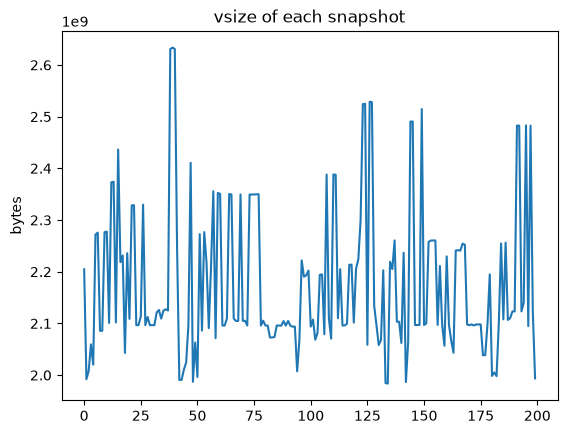

In [15]:
"""Run to plot the raw values of vsize""";
df_mystery['vsize'].plot(kind='line')
plt.title('vsize of each snapshot')
plt.ylabel('bytes')

The tick labels on the y axis are in the billions (`1e9` at the top of the axis).

A **box plot** summarizes a column in one picture:

* the box spans the middle half of the values, from the 25% value to the 75% value,
* the line inside the box is the median (the 50% value),
* the whiskers reach out to the last values within 1.5 box-widths of the box, and
* points beyond the whiskers are drawn individually as outliers.

**EXERCISE 5**: Draw a box plot of `vsize`, then print `df_mystery['vsize'].describe()` in the next cell.
Which numbers from `describe()` can you find in the plot?

<Axes: >

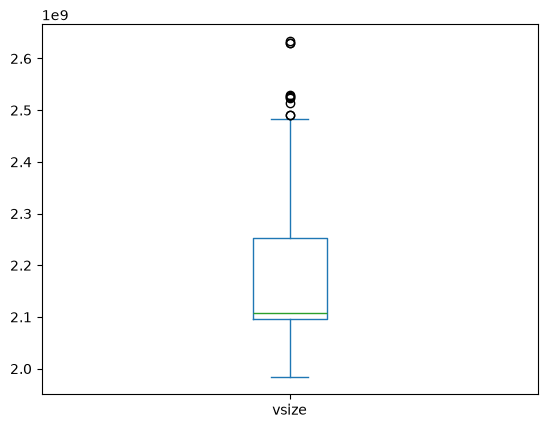

In [17]:
"""Draw a box plot of vsize""";
#df_mystery['vsize'].plot(kind=#TODO)

df_mystery["vsize"].plot(kind="box")

In [18]:
"""Print the descriptive statistics of vsize""";
#print(#TODO)

print(df_mystery["vsize"].describe())

count    2.000000e+02
mean     2.175793e+09
std      1.417478e+08
min      1.983623e+09
25%      2.095809e+09
50%      2.107628e+09
75%      2.252854e+09
max      2.633560e+09
Name: vsize, dtype: float64


### 5.3 Counting Categories: Bar and Pie Charts

`value_counts()` counts how many rows hold each value of a column. The result is a Series whose
labels are the app names, so pandas uses them for the bars automatically.

ApplicationName
Facebook    121
WhatsApp     79
Name: count, dtype: int64


Text(0, 0.5, 'Rows')

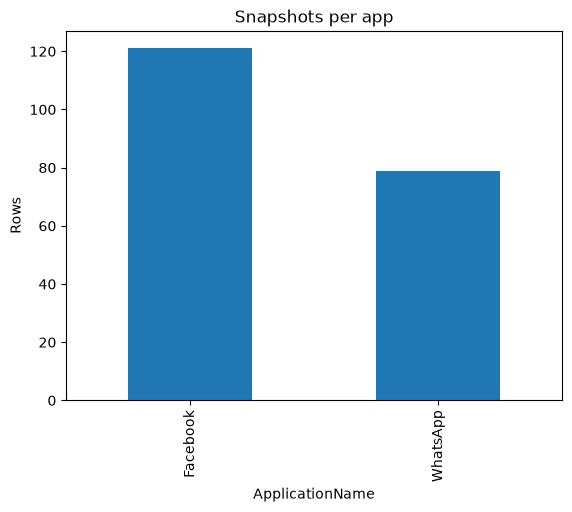

In [16]:
"""Run to count the snapshots of each app and draw a bar chart""";
counts = df_mystery['ApplicationName'].value_counts()
print(counts)

counts.plot(kind='bar')
plt.title('Snapshots per app')
plt.ylabel('Rows')

**EXERCISE 6**: Show the same counts as a pie chart with a title. (Hint: only the `kind` changes.)

Text(0.5, 1.0, 'Snapshots per app')

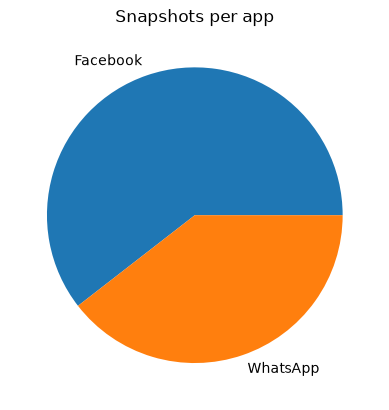

In [19]:
"""Use this cell for Exercise 6""";
#counts.plot(kind=#TODO)
#plt.title(#TODO)

counts.plot(kind="pie")
plt.title("Snapshots per app")

### 5.4 How Values Are Spread: Histograms

A **histogram** splits the range of a column into equal bins and draws one bar per bin,
as tall as the number of values that fall in it.

**EXERCISE 7**: Draw a histogram of `CPU_USAGE` with 20 bins, using `kind='hist'` and `bins=20`.
Most values are small, but one snapshot reaches 4.99. How does that show in the histogram?

<Axes: ylabel='Frequency'>

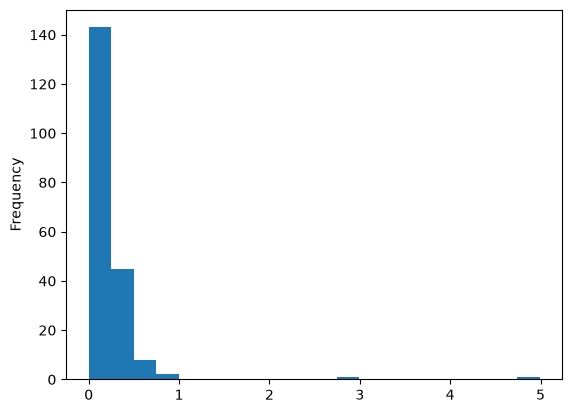

In [20]:
"""Use this cell for Exercise 7""";
#df_mystery['CPU_USAGE'].plot(kind=#TODO, bins=#TODO)

df_mystery["CPU_USAGE"].plot(kind="hist", bins=20)

### 5.5 Comparing the Two Apps

seaborn draws statistical plots straight from a DataFrame. Given a category column for `x` and a
number column for `y`, `seaborn.boxplot` draws one box per category side by side.

Text(0.5, 1.0, 'Threads per snapshot')

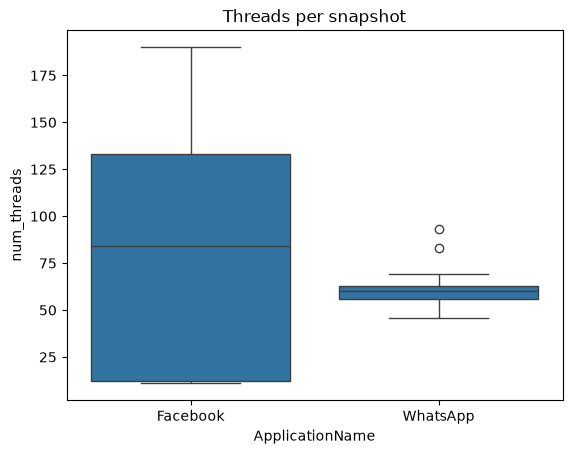

In [21]:
"""Run to compare the number of threads of the two apps""";
seaborn.boxplot(x='ApplicationName', y='num_threads', data=df_mystery)
plt.title('Threads per snapshot')

**QUESTION**: Which app typically runs more threads? Which app's values are more spread out?

The app with the higher median typically runs more threads. The app with the wider and longer whiskers generally has more spread out values.


**CHALLENGE (optional)**: Draw a bar chart of the **average** `CPU_USAGE` of each app.
Hint: `df_mystery.groupby('ApplicationName')['CPU_USAGE'].mean()` computes the averages
(grouping is covered in Session 2); plot that Series with `kind='bar'`.

<Axes: xlabel='ApplicationName'>

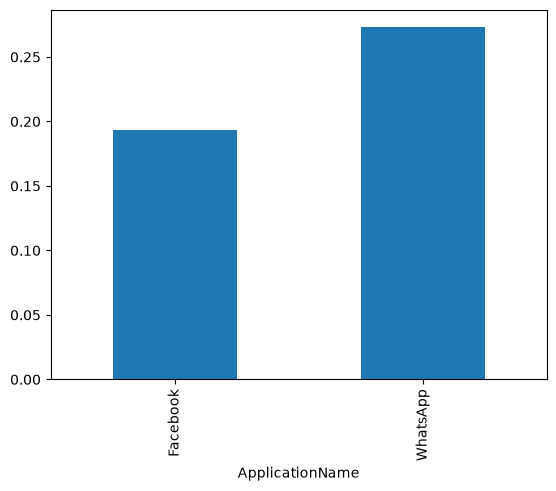

In [22]:
"""Use this cell for the challenge""";
#TODO

avg_cpu = df_mystery.groupby("ApplicationName")["CPU_USAGE"].mean()
avg_cpu.plot(kind="bar")

<a id="sec-Summary"></a>[(back to top)](#TOC)
## 6. Summary & Further Resources

| Task | matplotlib | pandas |
|:---|:---|:---|
| Line graph | `plt.plot(x, y)` | `series.plot(kind='line')` |
| Bar chart | `plt.bar(x, heights)` | `series.plot(kind='bar')` |
| Pie chart | `plt.pie(values, labels=...)` | `series.plot(kind='pie')` |
| Box plot | `plt.boxplot(values)` | `series.plot(kind='box')` |
| Histogram | `plt.hist(values, bins=20)` | `series.plot(kind='hist', bins=20)` |
| Title, axis labels | `plt.title`, `plt.xlabel`, `plt.ylabel` | the same, after `.plot()` |

* pandas: [Chart visualization](https://pandas.pydata.org/docs/user_guide/visualization.html) in the user guide
* matplotlib: [Pyplot tutorial](https://matplotlib.org/stable/tutorials/pyplot.html)
* seaborn: [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)